# Lab 05 Tasks — Image Segmentation

Images come from the links given in *Image Link – Lab 05 Tasks.pdf* and are stored in `images/`:

| Task | Image |
|---|---|
| 1, 2 | `sudoku.png` (OpenCV samples) |
| 3, 7, 8 | `water_coins.jpg` (OpenCV watershed tutorial) |
| 4, 5 | `smarties.png` (OpenCV samples) |
| 6 | `brain_mri.png` (MRI input figure from the TSI Journals region-growing article, cropped to the scan) |
| 9 | `dog.jpeg` (Packt *Computer-Vision-Projects-with-OpenCV-and-Python-3*) |
| 10 | `smarties.png` (recommended in the sheet) |

Every task saves its final result into `outputs/`.

In [1]:
%pip install opencv-python matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\azama\AppData\Local\Temp\claude\C--Users-azama-VS-Code-PROJECTS-01-Academic-Projects-Computer-Vision\a3c19062-200d-4788-a4f3-77cf48e11a00\scratchpad\venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import os
from collections import deque

import cv2
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)   # folder where every task saves its final output


def show(images, titles, cols=None, size=4):
    # Helper: shows images in a grid. 2D arrays are drawn in grayscale, 3-channel BGR images in colour.
    cols = cols or len(images)
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(size * cols, size * rows))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        if img.ndim == 2:
            plt.imshow(img, cmap='gray')
        else:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(title, fontsize=11)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## Task 1 — Automated Inspection of a Document Under Uneven Lighting

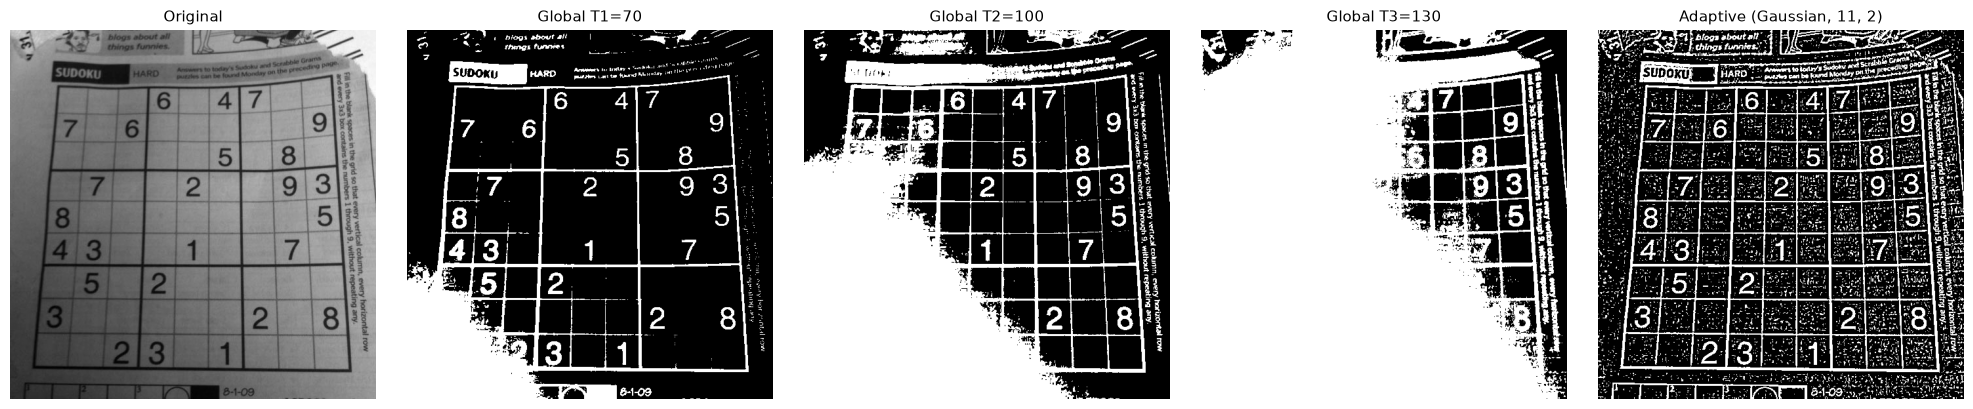

True

In [3]:
# 1. Load the document in grayscale.
doc = cv2.imread('images/sudoku.png', cv2.IMREAD_GRAYSCALE)

# 2. Global thresholding with three different values.
#    THRESH_BINARY_INV makes the dark ink white (foreground) and the paper black.
T1, T2, T3 = 70, 100, 130
_, g1 = cv2.threshold(doc, T1, 255, cv2.THRESH_BINARY_INV)
_, g2 = cv2.threshold(doc, T2, 255, cv2.THRESH_BINARY_INV)
_, g3 = cv2.threshold(doc, T3, 255, cv2.THRESH_BINARY_INV)

# 4. Adaptive thresholding: each pixel gets its own threshold = Gaussian-weighted mean of its
#    11x11 neighbourhood minus C=2, so it follows the lighting change across the page.
adaptive = cv2.adaptiveThreshold(doc, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, 11, 2)

# 3 & 5. Compare everything side by side: Original -> Global T1 -> T2 -> T3 -> Adaptive
show([doc, g1, g2, g3, adaptive],
     ['Original', f'Global T1={T1}', f'Global T2={T2}', f'Global T3={T3}', 'Adaptive (Gaussian, 11, 2)'])

cv2.imwrite('outputs/task1_adaptive_mask.png', adaptive)

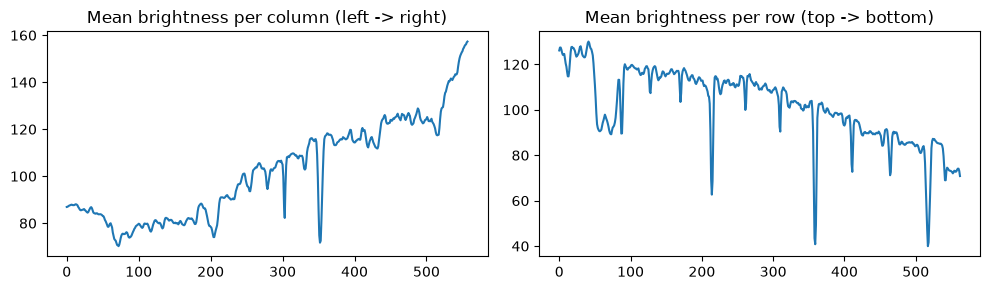

In [4]:
# 6. Where does global thresholding fail? Brightness profile of the page:
#    average intensity of each column and each row (paper is the brightest part).
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); plt.plot(doc.mean(axis=0)); plt.title('Mean brightness per column (left -> right)')
plt.subplot(1, 2, 2); plt.plot(doc.mean(axis=1)); plt.title('Mean brightness per row (top -> bottom)')
plt.tight_layout(); plt.show()

### Parameters and observations

| Setting | Value | Why |
|---|---|---|
| Global T1 / T2 / T3 | 70 / 100 / 130 | Spread over the range where paper (~75–160) and ink overlap |
| Adaptive | Gaussian, blockSize 11, C 2 | 11 px is about one stroke + surrounding paper; C=2 is the standard starting value |

- **T1 = 70** is the best global result: digits and grid are readable, but the darker bottom-left corner still turns into a white blob.
- **T2 = 100** and **T3 = 130** get worse: large parts of the left and bottom of the page become white because the *paper itself* is darker than the threshold there. Only the bright right side survives.
- **Adaptive** keeps every digit and grid line across the whole page, with only light speckle inside cells (fixed in Task 2).

**Regions that make global thresholding fail:** the brightness plots show the page goes from ~75 on the left to ~160 on the right, and from ~125 at the top to ~70 at the bottom. The **left side and bottom-left corner** (shadowed) are where the paper is as dark as the ink.

**Most usable mask:** adaptive Gaussian thresholding (tuned to blockSize 11, C 5 in Task 2).

**Why does a single threshold struggle when illumination changes?** A global threshold assumes the paper has the same brightness everywhere. Here the paper in the shadowed corner is darker than the ink in the bright corner, so no single value can separate ink from paper in both places: a low value loses text in the dark area, a high value turns the dark paper into "text". Adaptive thresholding compares each pixel only to its local neighbourhood, so the lighting change cancels out.

## Task 2 — Choosing the Correct Adaptive Threshold Strategy

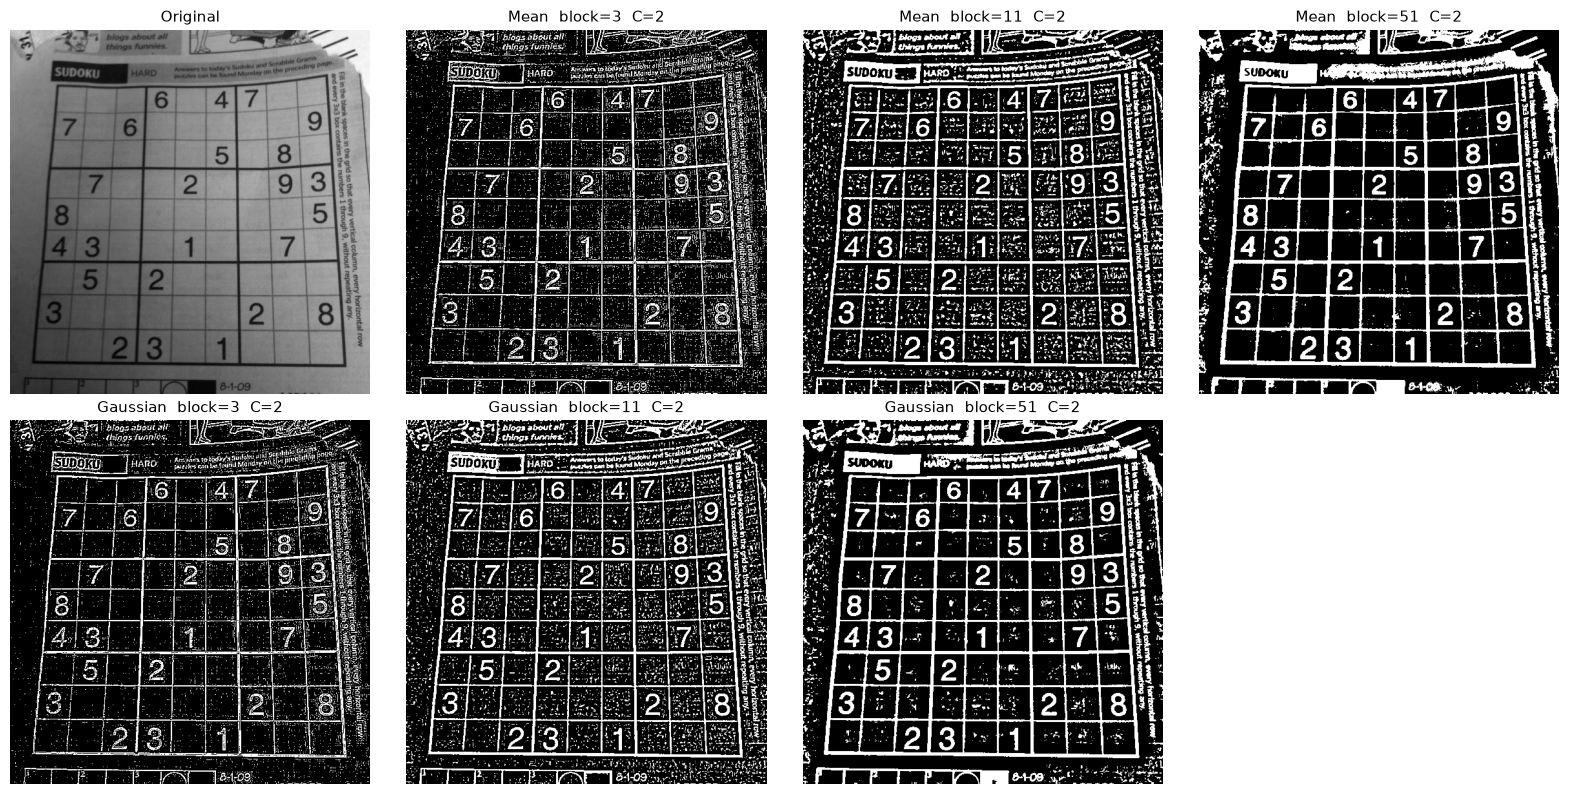

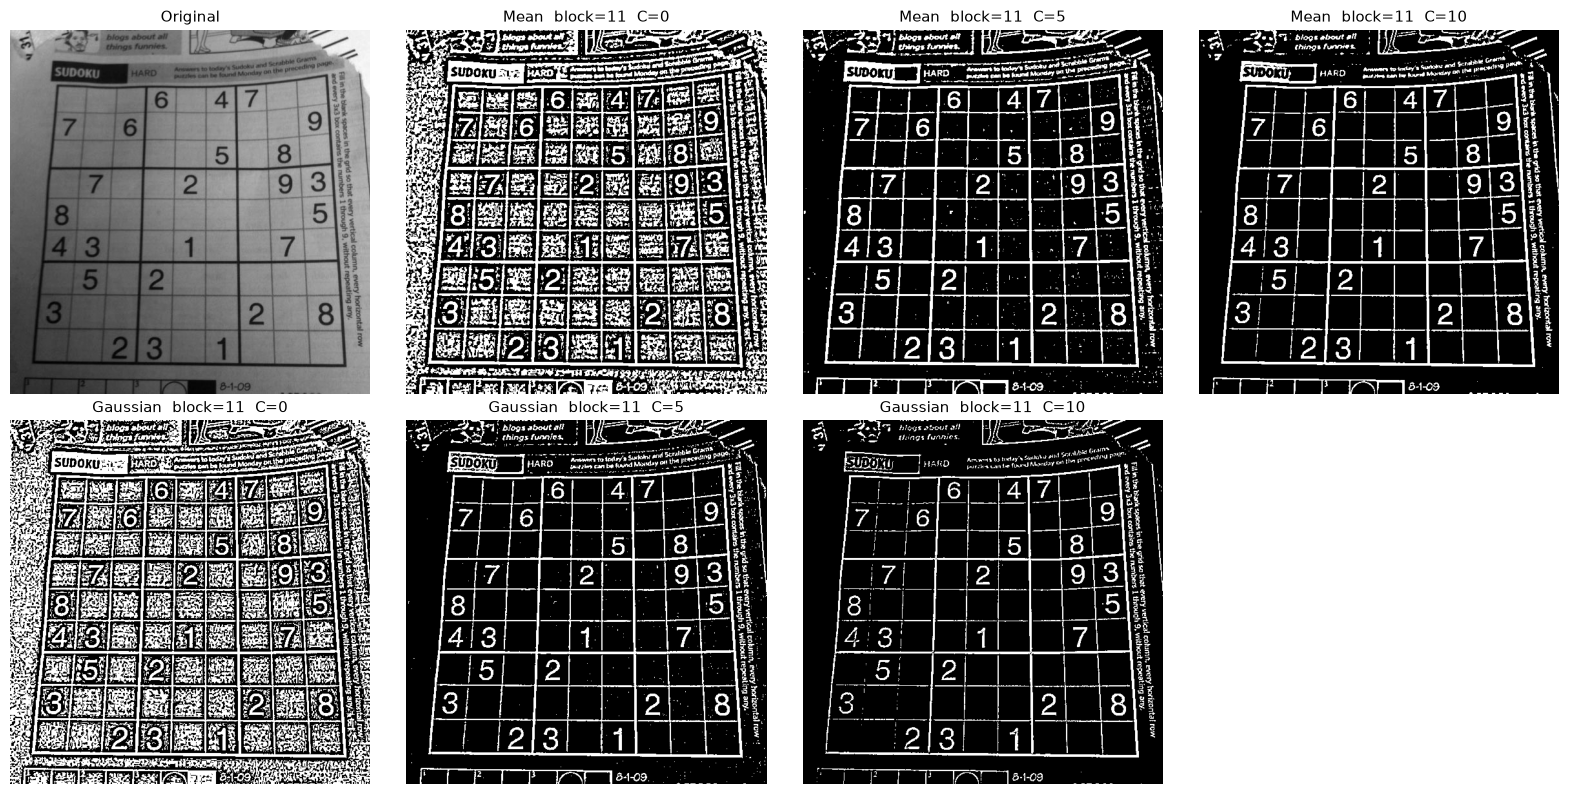

In [5]:
methods = {'Mean': cv2.ADAPTIVE_THRESH_MEAN_C, 'Gaussian': cv2.ADAPTIVE_THRESH_GAUSSIAN_C}

# Experiment A: change the neighbourhood (blockSize) while C stays 2.
blocks = [3, 11, 51]
imgs, titles = [], []
for name, m in methods.items():
    for b in blocks:
        imgs.append(cv2.adaptiveThreshold(doc, 255, m, cv2.THRESH_BINARY_INV, b, 2))
        titles.append(f'{name}  block={b}  C=2')
show([doc] + imgs, ['Original'] + titles, cols=4)

# Experiment B: change C while blockSize stays 11.
Cs = [0, 5, 10]
imgs, titles = [], []
for name, m in methods.items():
    for c in Cs:
        imgs.append(cv2.adaptiveThreshold(doc, 255, m, cv2.THRESH_BINARY_INV, 11, c))
        titles.append(f'{name}  block={11}  C={c}')
show([doc] + imgs, ['Original'] + titles, cols=4)

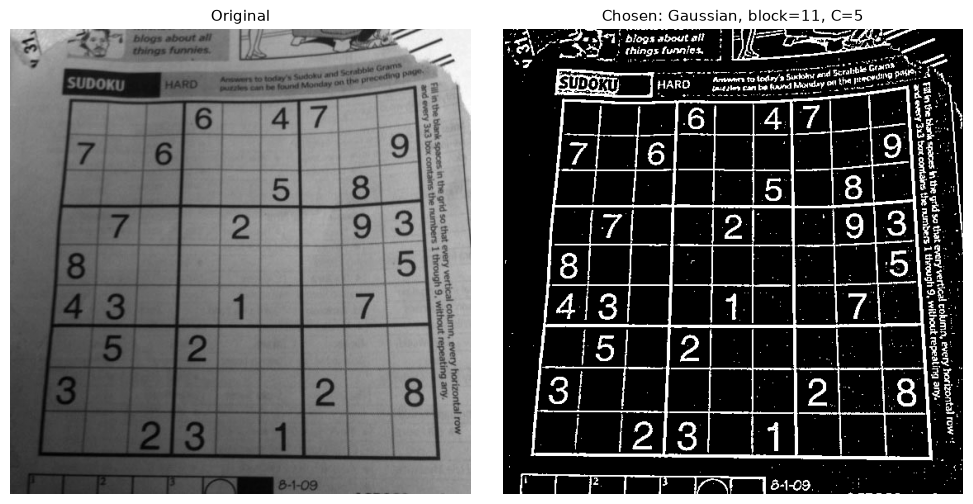

True

In [6]:
# Final choice (see analysis below).
best = cv2.adaptiveThreshold(doc, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 5)
show([doc, best], ['Original', 'Chosen: Gaussian, block=11, C=5'], size=5)
cv2.imwrite('outputs/task2_best_adaptive.png', best)

### Parameter comparison

| Method | blockSize | C | Small noise specks (< 15 px) | Observation |
|---|---|---|---|---|
| Mean | 3 | 2 | 7474 | Only thin outlines of strokes, grid broken |
| Mean | 11 | 2 | 2418 | Text complete, speckle inside cells |
| Mean | 51 | 2 | 412 | Thick bold strokes, dark blobs at page edge and shadows |
| Gaussian | 3 | 2 | 5695 | Same hollow outlines as mean |
| Gaussian | 11 | 2 | 4373 | Text complete, speckle inside cells |
| Gaussian | 51 | 2 | 906 | Bold strokes, edge noise |
| Mean | 11 | 0 | 651 | Paper texture becomes white everywhere (44.6 % white) |
| Mean | 11 | 5 | 615 | Clean text |
| Mean | 11 | 10 | 133 | Cleanest, strokes start to thin |
| Gaussian | 11 | 0 | 1024 | Very noisy (49.3 % white) |
| Gaussian | 11 | 5 | 621 | Clean text, strokes slightly thinner than mean |
| Gaussian | 11 | 10 | 290 | Some thin/faint digits in the dark corner |

(Speck counts were measured with `cv2.connectedComponentsWithStats` on each mask.)

1. **Neighbourhood too small (3):** the window sees only part of a stroke, so the local mean is already "ink" and only stroke borders pass — characters become hollow/broken.
2. **Neighbourhood too large (51):** the window behaves like a global threshold again; strokes get fat and shadows / page edges come back as black blobs.
3. **Increasing C:** the local threshold is lowered by C, so only pixels clearly darker than their surroundings survive. C = 0 keeps paper texture (heavy noise), C = 5 removes it, C = 10 starts to erase thin strokes.
4. **Cleanest combination:** blockSize **11**, C **5** (saved in `outputs/task2_best_adaptive.png`).
5. **Better method on this image:** both are very close at C = 5. **Gaussian** was chosen: its weights favour the centre pixel, so it reacts more to fine strokes and gives slightly thinner, sharper digits; mean gives slightly bolder strokes with similar noise.

## Task 3 — Quality-Control System Using Otsu's Thresholding

Original                   -> Otsu threshold = 162


C:\Users\azama\AppData\Local\Temp\ipykernel_27356\1672723657.py:26: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.subplot(1, 3, 2); plt.hist(img.ravel(), 256, [0, 256], color='gray')


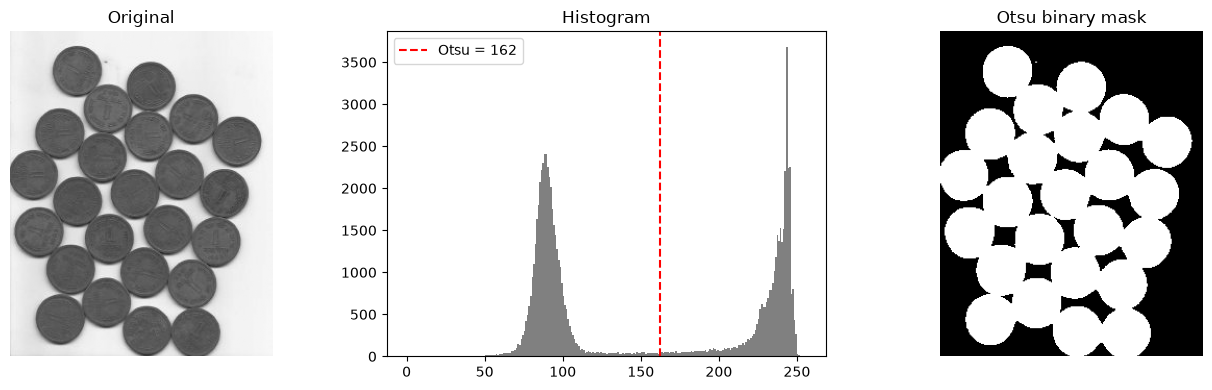

Low contrast (x0.6 + 50)   -> Otsu threshold = 147


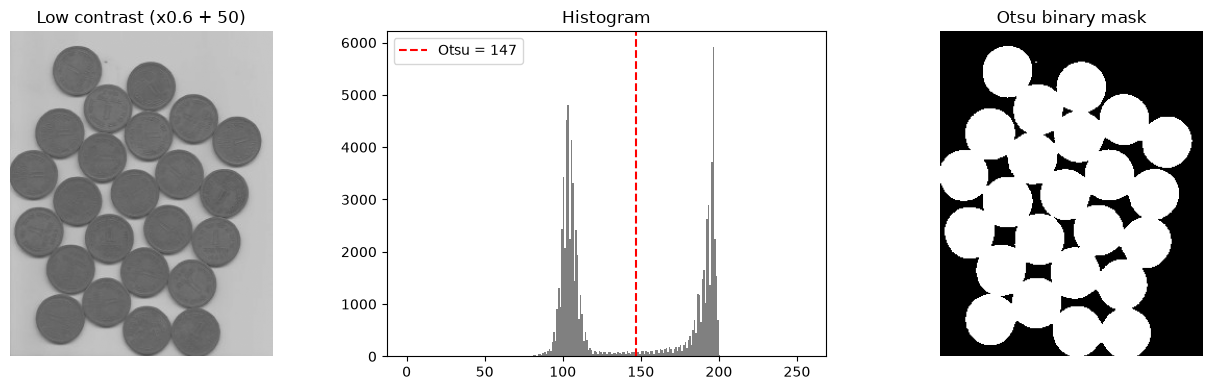

Gaussian blur 5x5          -> Otsu threshold = 162


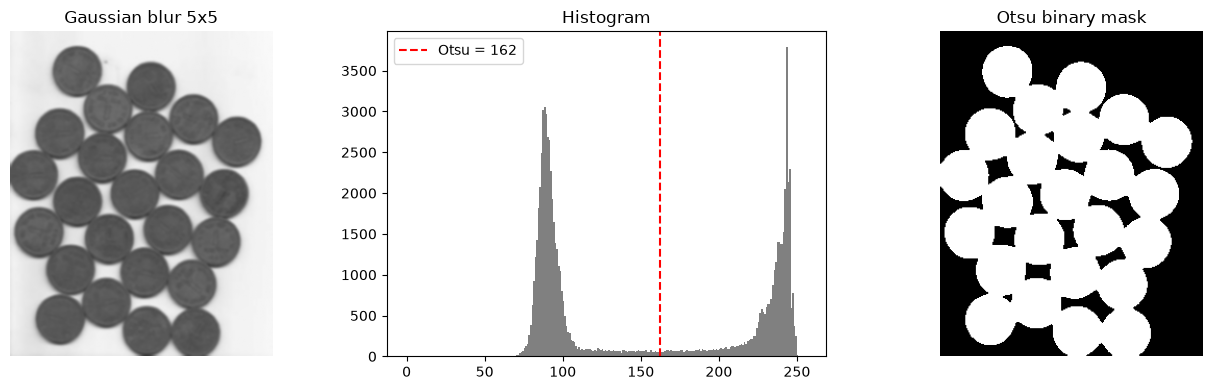

True

In [7]:
coins = cv2.imread('images/water_coins.jpg')
gray = cv2.cvtColor(coins, cv2.COLOR_BGR2GRAY)          # 1. grayscale


def otsu(img):
    # Otsu picks the threshold that best separates the histogram into two classes
    # (we pass 0 as the threshold; OpenCV ignores it and returns the one Otsu found).
    t, mask = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return t, mask


# Three versions of the same picture: original, lower contrast, and blurred.
versions = {
    'Original': gray,
    'Low contrast (x0.6 + 50)': cv2.convertScaleAbs(gray, alpha=0.6, beta=50),
    'Gaussian blur 5x5': cv2.GaussianBlur(gray, (5, 5), 0),
}

for name, img in versions.items():
    t, mask = otsu(img)
    print(f'{name:26s} -> Otsu threshold = {t:.0f}')

    # Original -> Histogram (with Otsu line) -> Otsu binary mask
    plt.figure(figsize=(14, 4))
    plt.subplot(1, 3, 1); plt.imshow(img, cmap='gray', vmin=0, vmax=255); plt.title(name); plt.axis('off')
    plt.subplot(1, 3, 2); plt.hist(img.ravel(), 256, [0, 256], color='gray')
    plt.axvline(t, color='red', linestyle='--', label=f'Otsu = {t:.0f}'); plt.legend(); plt.title('Histogram')
    plt.subplot(1, 3, 3); plt.imshow(mask, cmap='gray'); plt.title('Otsu binary mask'); plt.axis('off')
    plt.tight_layout(); plt.show()

cv2.imwrite('outputs/task3_otsu_mask.png', otsu(gray)[1])

### Results

| Version | Otsu threshold |
|---|---|
| Original | **162** |
| Low contrast (`0.6·I + 50`) | **147** |
| Gaussian blur 5×5 | **162** |

The histogram has two clear peaks: coins (~90) and white background (~245). Otsu places the threshold in the valley between them. When the contrast is reduced both peaks move closer (~105 and ~195) and Otsu **automatically moves the threshold to 147**; blurring does not move the peaks, so the threshold stays 162. In all three cases the mask is the same clean coin shape.

**Why is Otsu useful when the threshold is unknown?** Otsu tries every possible threshold and picks the one that best separates the histogram into two classes (minimum within-class variance). It needs no manual value, and — as seen above — it adapts when lighting or contrast changes, which a hard-coded threshold (e.g. 162) would not do on the low-contrast image.

## Task 4 — Sorting Objects by Color

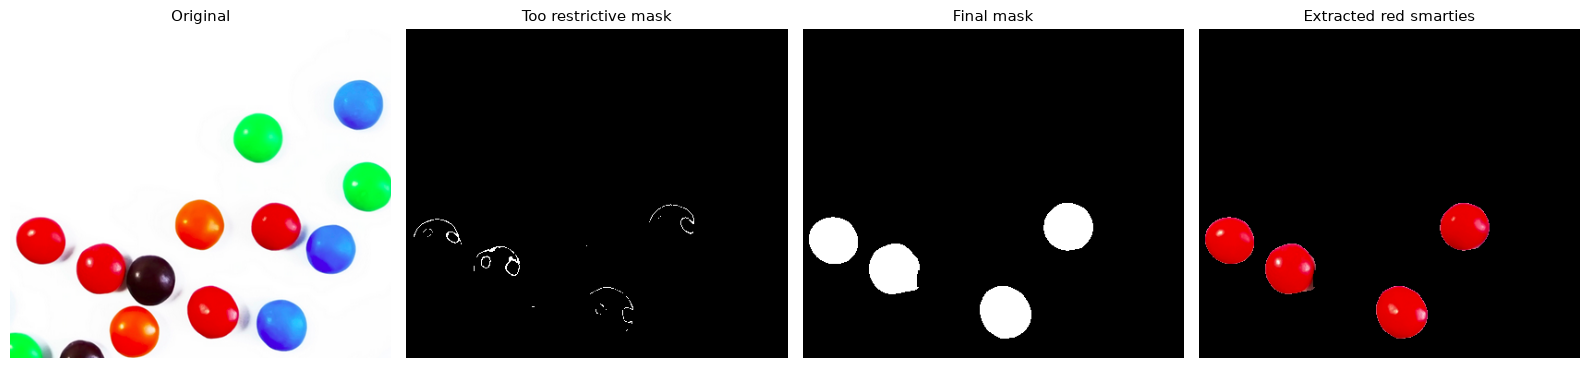

White pixels  restrictive: 537 | final: 9221 | red objects found: 4


True

In [8]:
sm = cv2.imread('images/smarties.png')                  # 1. load in colour
hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)               # 2. convert to HSV

# Target: the RED smarties. Red sits at both ends of OpenCV's hue circle (0-180),
# so the red range needs two hue bands. Measured hues: red sweets ~170-180 and 0, orange sweets ~0-17.

# 3/4. Too-restrictive mask: narrow hue band and very high saturation/brightness only.
tight = cv2.inRange(hsv, np.array([175, 230, 220]), np.array([180, 255, 255]))

# 5. After experimenting: hue 160-180 plus hue 0-1 (red wraps around), S/V lowered to 100 so shaded
#    sides are kept, but V >= 100 still rejects the dark-brown sweets. Hue stops at 1 to avoid orange.
final = cv2.bitwise_or(cv2.inRange(hsv, np.array([0, 100, 100]), np.array([1, 255, 255])),
                       cv2.inRange(hsv, np.array([160, 100, 100]), np.array([180, 255, 255])))

# Clean-up: closing fills the white specular highlights; tiny blobs (shaded orange rims) are removed by area.
final = cv2.morphologyEx(final, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
n, labels, stats, _ = cv2.connectedComponentsWithStats(final)
final = np.isin(labels, [k for k in range(1, n) if stats[k, cv2.CC_STAT_AREA] > 800]).astype(np.uint8) * 255

# 6. Extract the red objects from the original image with the mask.
extracted = cv2.bitwise_and(sm, sm, mask=final)

show([sm, tight, final, extracted],
     ['Original', 'Too restrictive mask', 'Final mask', 'Extracted red smarties'])
print('White pixels  restrictive:', cv2.countNonZero(tight), '| final:', cv2.countNonZero(final),
      '| red objects found:', cv2.connectedComponents(final)[0] - 1)
cv2.imwrite('outputs/task4_red_extracted.png', extracted)

### Parameters

| Mask | Lower (H, S, V) | Upper (H, S, V) | Result |
|---|---|---|---|
| Too restrictive | (175, 230, 220) | (180, 255, 255) | 537 px — only thin bright arcs |
| Final | (0,100,100)–(1,255,255) **OR** (160,100,100)–(180,255,255), then closing 9×9 and blobs > 800 px | | 9221 px — all **4** red sweets |

Hue values were measured on each sweet: red sweets sit at hue ~169–180 and 0, orange sweets at 0–17, brown sweets have V ≈ 55.

**Why the restrictive mask fails:**
- Red wraps around the hue circle; a single band 175–180 misses all red pixels with hue 169–174 and 0.
- S ≥ 230 and V ≥ 220 only keep the brightest, most saturated part of each sweet. The shaded side of a sphere is darker, so it is dropped and the sweet breaks into fragments.

**Final mask choices:** S/V lowered to 100 keeps the shaded sides, while V ≥ 100 still rejects the dark brown sweets. The low-hue band stops at 1 because orange starts there. White specular highlights have no colour, so closing fills them; the remaining small crescents (shaded rims of orange sweets) are removed by an area filter.

## Task 5 — Detecting the Boundary of a Manufactured Part

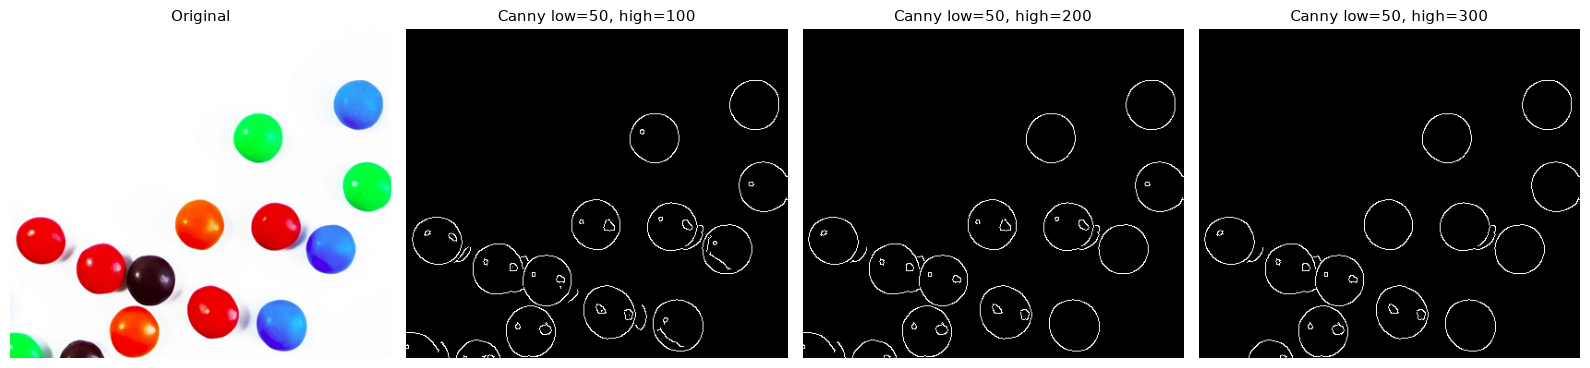

True

In [9]:
gray = cv2.cvtColor(sm, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)   # remove small noise before finding edges

# Canny hysteresis: gradient > high -> strong edge (kept);
# low < gradient < high -> weak edge, kept ONLY if connected to a strong edge; < low -> dropped.
pairs = [(50, 100), (50, 200), (50, 300)]   # low fixed, high increased
edges = [cv2.Canny(blur, lo, hi) for lo, hi in pairs]

show([sm] + edges, ['Original'] + [f'Canny low={lo}, high={hi}' for lo, hi in pairs])
cv2.imwrite('outputs/task5_canny_50_200.png', edges[1])

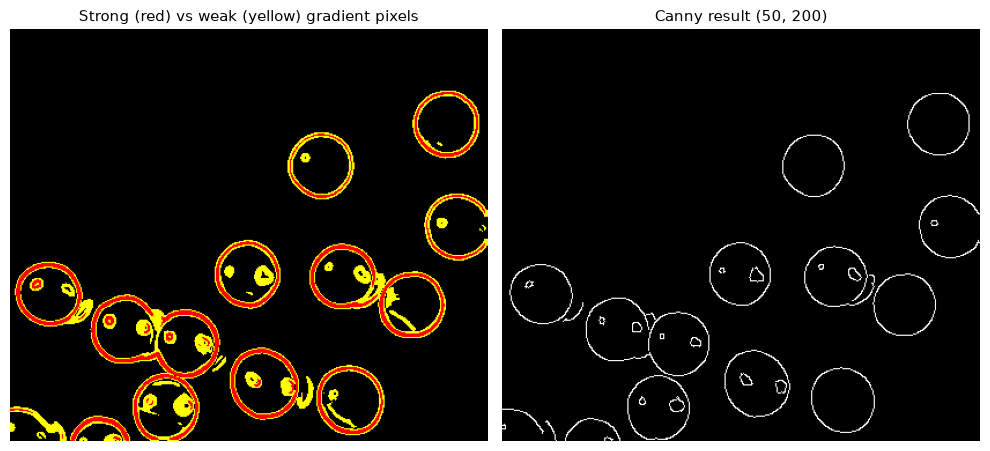

In [10]:
# Where are the strong and weak edge pixels? (Sobel gradient magnitude, same 3x3 operator Canny uses)
gx = cv2.Sobel(blur, cv2.CV_64F, 1, 0)
gy = cv2.Sobel(blur, cv2.CV_64F, 0, 1)
mag = np.hypot(gx, gy)

lo, hi = 50, 200
view = np.zeros_like(sm)
view[(mag >= lo) & (mag < hi)] = (0, 255, 255)   # weak  -> yellow
view[mag >= hi] = (0, 0, 255)                    # strong -> red
show([view, edges[1]], ['Strong (red) vs weak (yellow) gradient pixels', 'Canny result (50, 200)'], size=5)

### Parameters

Gaussian blur 5×5 before Canny (removes pixel noise). Low threshold fixed at **50**, high threshold **100 → 200 → 300**.

| Pair | Edge pixels | Separate edge pieces |
|---|---|---|
| 50 / 100 | 3292 | 47 |
| 50 / 200 | 2991 | 31 |
| 50 / 300 | 2773 | 23 |

- **Strong edges** (red in the gradient map, above the high threshold): the outlines of every sweet against the white background — kept in all three results.
- **Weak edges** (yellow, between low and high): highlight rings inside the sweets and soft shadows next to them. With high = 100 many of these become strong and show as small circles and shadow arcs inside/next to the sweets.
- **Unwanted edges:** highlight blobs and shadow crescents (most visible with 50/100).
- **Missing edges:** with high = 300 some sweet outlines lose short segments where two sweets touch or where the sweet meets its own shadow, because those contrasts are weaker.

**How the two thresholds change the result:** a pixel above *high* is an edge; a pixel between *low* and *high* is kept only if it is connected to a strong edge (hysteresis). Raising *high* with *low* fixed means fewer starting points, so fewer weak chains are accepted — less clutter but more gaps. Lowering *low* would let chains grow further from each strong edge. **50 / 200** gave complete outlines with little clutter and was saved.

## Task 6 — Segmenting a Region Inside a Medical Image

Lesion seed (160, 220) | seed intensity = 212 | region sizes (px): [3284, 4442, 5053]


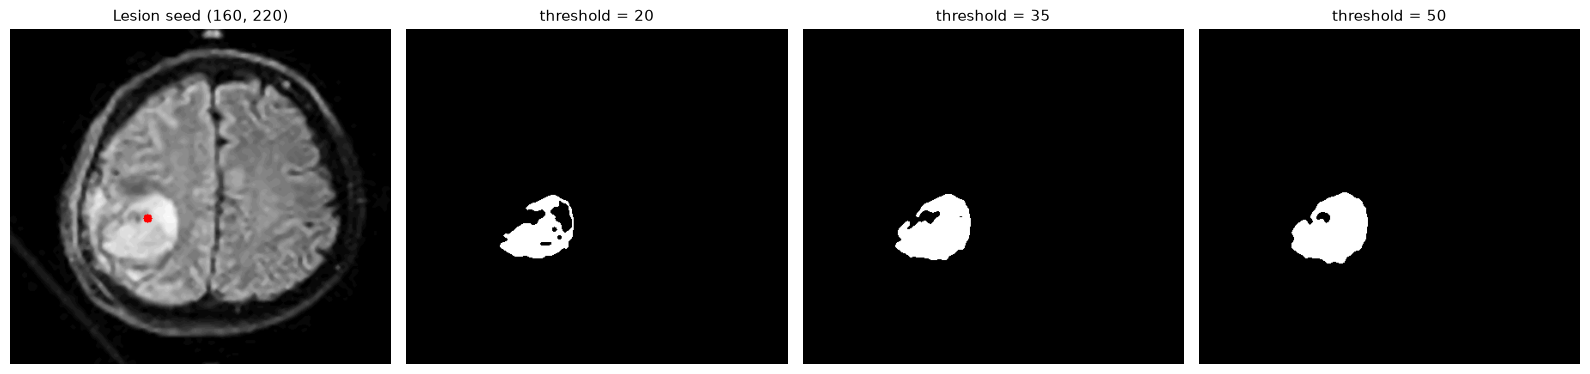

Healthy tissue seed (300, 200) | seed intensity = 148 | region sizes (px): [8473, 47151, 54151]


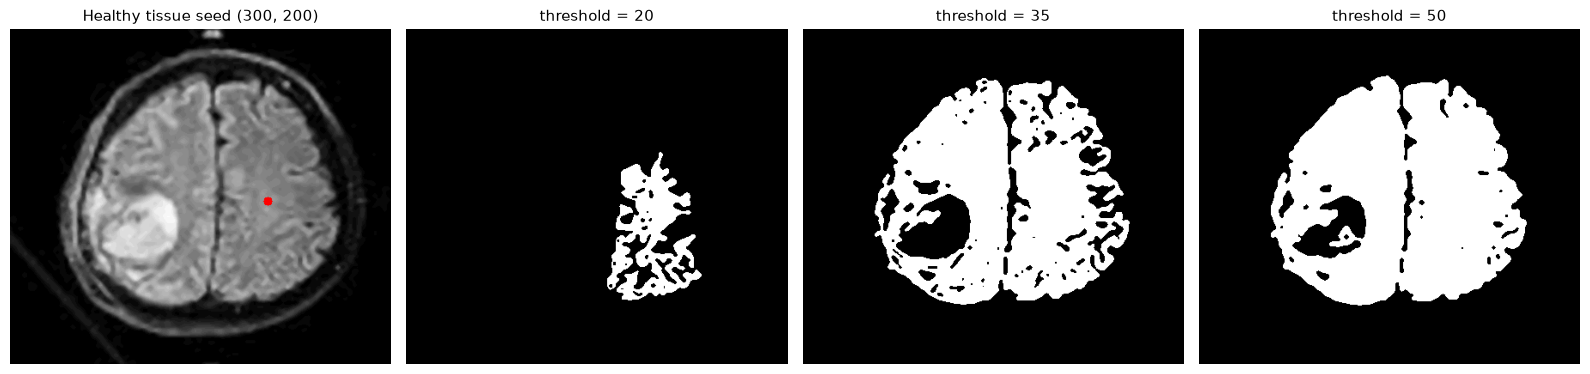

True

In [11]:
mri = cv2.imread('images/brain_mri.png', cv2.IMREAD_GRAYSCALE)   # 1. grayscale

# Median blur 5x5 removes the speckle noise of the scan, so single noisy pixels do not block the growth.
mri = cv2.medianBlur(mri, 5)


def region_grow(img, seed, thresh):
    # Grows a region from 'seed' (x, y): a 4-connected neighbour joins the region
    # if |neighbour intensity - seed intensity| <= thresh. Returns a binary mask.
    h, w = img.shape
    mask = np.zeros((h, w), np.uint8)
    seed_val = int(img[seed[1], seed[0]])
    queue = deque([seed])
    mask[seed[1], seed[0]] = 255
    while queue:
        x, y = queue.popleft()
        for nx, ny in ((x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)):
            if 0 <= nx < w and 0 <= ny < h and mask[ny, nx] == 0 \
                    and abs(int(img[ny, nx]) - seed_val) <= thresh:
                mask[ny, nx] = 255
                queue.append((nx, ny))
    return mask


# 2. Two seed locations: inside the bright lesion, and in normal tissue of the other hemisphere.
seeds = {'Lesion seed (160, 220)': (160, 220), 'Healthy tissue seed (300, 200)': (300, 200)}
thresholds = [20, 35, 50]   # 3 region-growing thresholds

for name, seed in seeds.items():
    masks = [region_grow(mri, seed, t) for t in thresholds]
    marked = cv2.cvtColor(mri, cv2.COLOR_GRAY2BGR)
    cv2.circle(marked, seed, 5, (0, 0, 255), -1)
    print(name, '| seed intensity =', mri[seed[1], seed[0]],
          '| region sizes (px):', [cv2.countNonZero(m) for m in masks])
    show([marked] + masks, [name] + [f'threshold = {t}' for t in thresholds])

cv2.imwrite('outputs/task6_lesion_region.png', region_grow(mri, (160, 220), 35))

### Parameters

Median blur 5×5 first (the scan has speckle noise). 4-connected growth; a neighbour joins if `|I(neighbour) − I(seed)| ≤ threshold`.

| Seed | Seed intensity | T = 20 | T = 35 | T = 50 |
|---|---|---|---|---|
| Lesion (160, 220) | 212 | 3284 px | 4442 px | 5053 px |
| Healthy tissue (300, 200) | 148 | 8473 px | 47151 px | 54151 px |

- **Lesion seed:** the bright lesion is grown cleanly. T = 20 leaves holes, T = 35 fills the lesion, T = 50 adds only a little more because the lesion (~200–250) is much brighter than the surrounding tissue (~130–150). T = 35 was saved.
- **Healthy seed:** T = 20 gives a small patch; T = 35 and 50 leak across almost the whole brain (both hemispheres), because normal tissue all has similar intensity and is connected.

**Why can changing the seed change the result so much?** The criterion is measured against the **seed's own intensity** and the region can only spread through **connected** pixels. A seed inside the lesion (212) only accepts bright pixels, so it stops at the lesion border. A seed in normal tissue (148) accepts the tissue range, which is connected all over the brain, so the same threshold produces a completely different (and much larger) region.

## Task 7 — Separating Touching Coins in an Automated Counting System

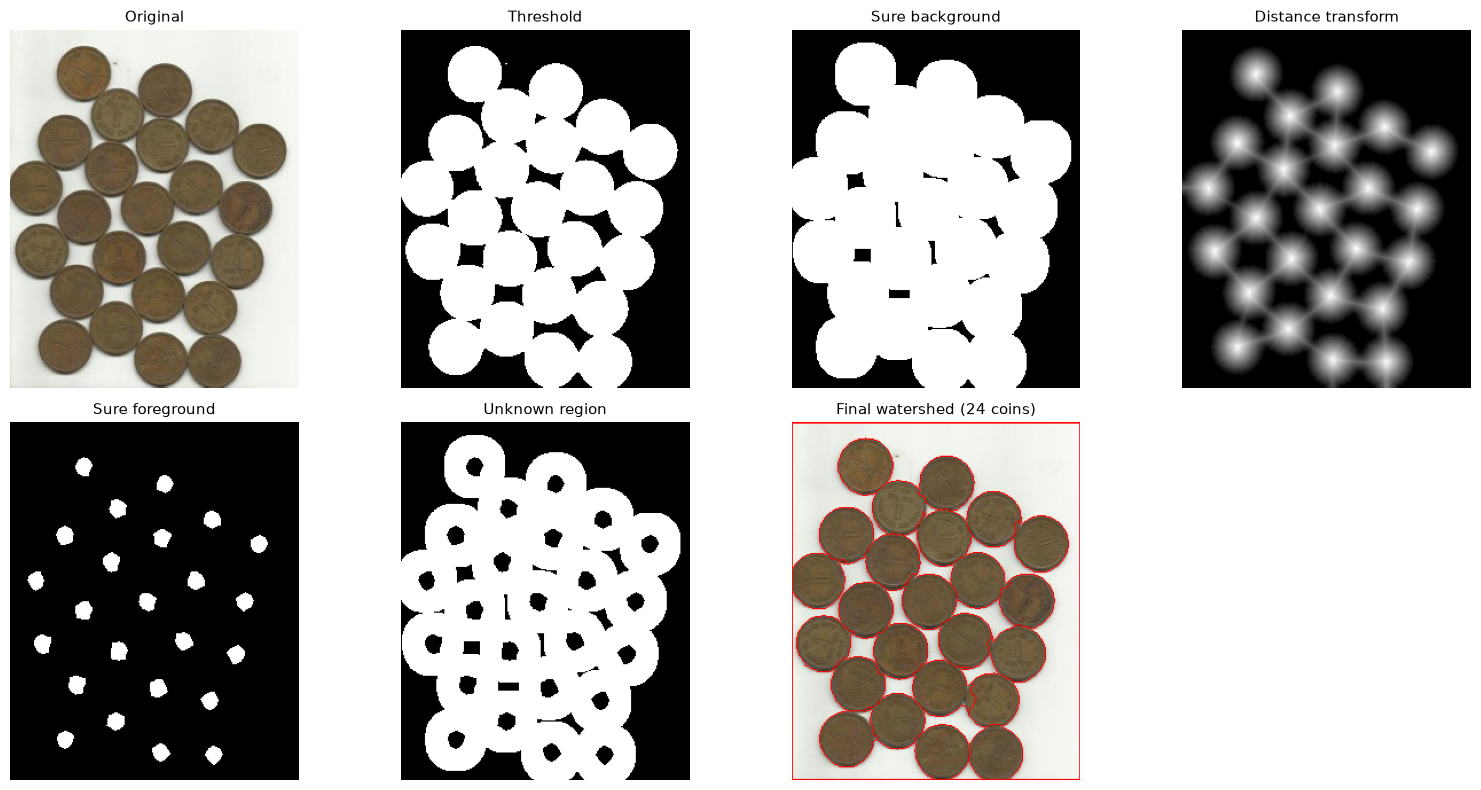

Connected regions in plain threshold: 2
Coins found by watershed           : 24


True

In [12]:
def watershed_coins(img, dist_ratio):
    # Marker-based watershed (stages from the OpenCV tutorial). Returns every stage for display.
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1-2. Preprocessing + thresholding (Otsu, coins become white).
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # 3. Noise removal: opening deletes small white specks.
    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

    # 4. Sure background: dilate so everything outside is definitely background.
    sure_bg = cv2.dilate(opening, kernel, iterations=3)

    # 5. Distance transform: each white pixel -> distance to nearest black pixel (coin centres are highest).
    dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

    # 6. Sure foreground: keep only pixels far from the edge (a fraction of the max distance).
    _, sure_fg = cv2.threshold(dist, dist_ratio * dist.max(), 255, 0)
    sure_fg = sure_fg.astype(np.uint8)

    # 7. Unknown region: between sure background and sure foreground (where coins touch).
    unknown = cv2.subtract(sure_bg, sure_fg)

    # 8. Marker labelling: each sure-foreground blob gets its own number; background = 1, unknown = 0.
    n_markers, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0

    # 9. Watershed floods from the markers; boundaries between regions get label -1.
    markers = cv2.watershed(img.copy(), markers)

    # 10. Boundary visualisation in red.
    result = img.copy()
    result[markers == -1] = (0, 0, 255)

    n_fg = n_markers - 1                               # minus the background label
    n_regions = len(np.unique(markers)) - 2            # minus background (1) and boundary (-1)
    return dict(thresh=thresh, sure_bg=sure_bg, dist=dist, sure_fg=sure_fg,
                unknown=unknown, result=result, n_fg=n_fg, n_regions=n_regions)


coins = cv2.imread('images/water_coins.jpg')
w = watershed_coins(coins, 0.7)
dist_view = cv2.normalize(w['dist'], None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

show([coins, w['thresh'], w['sure_bg'], dist_view, w['sure_fg'], w['unknown'], w['result']],
     ['Original', 'Threshold', 'Sure background', 'Distance transform', 'Sure foreground',
      'Unknown region', f"Final watershed ({w['n_regions']} coins)"], cols=4)

# Simple connected-component count on the threshold, for comparison (touching coins merge).
print('Connected regions in plain threshold:', cv2.connectedComponents(w['thresh'])[0] - 1)
print('Coins found by watershed           :', w['n_regions'])
cv2.imwrite('outputs/task7_watershed.png', w['result'])

### Parameters

Otsu threshold (inverted), opening 3×3 × 2, dilation 3×3 × 3 for sure background, distance transform `DIST_L2` mask 5, sure foreground at **0.7 × max distance** (OpenCV tutorial value).

**Result:** a plain threshold gives **2** connected regions (touching coins merge into one big blob). The watershed gives **24** regions — one per coin. Visually every touching pair has a red boundary along its contact line, so the touching coins are separated. (Watershed also marks the image border with −1, which is why a red frame appears around the image.)

## Task 8 — Tuning Watershed for Difficult Object Separation

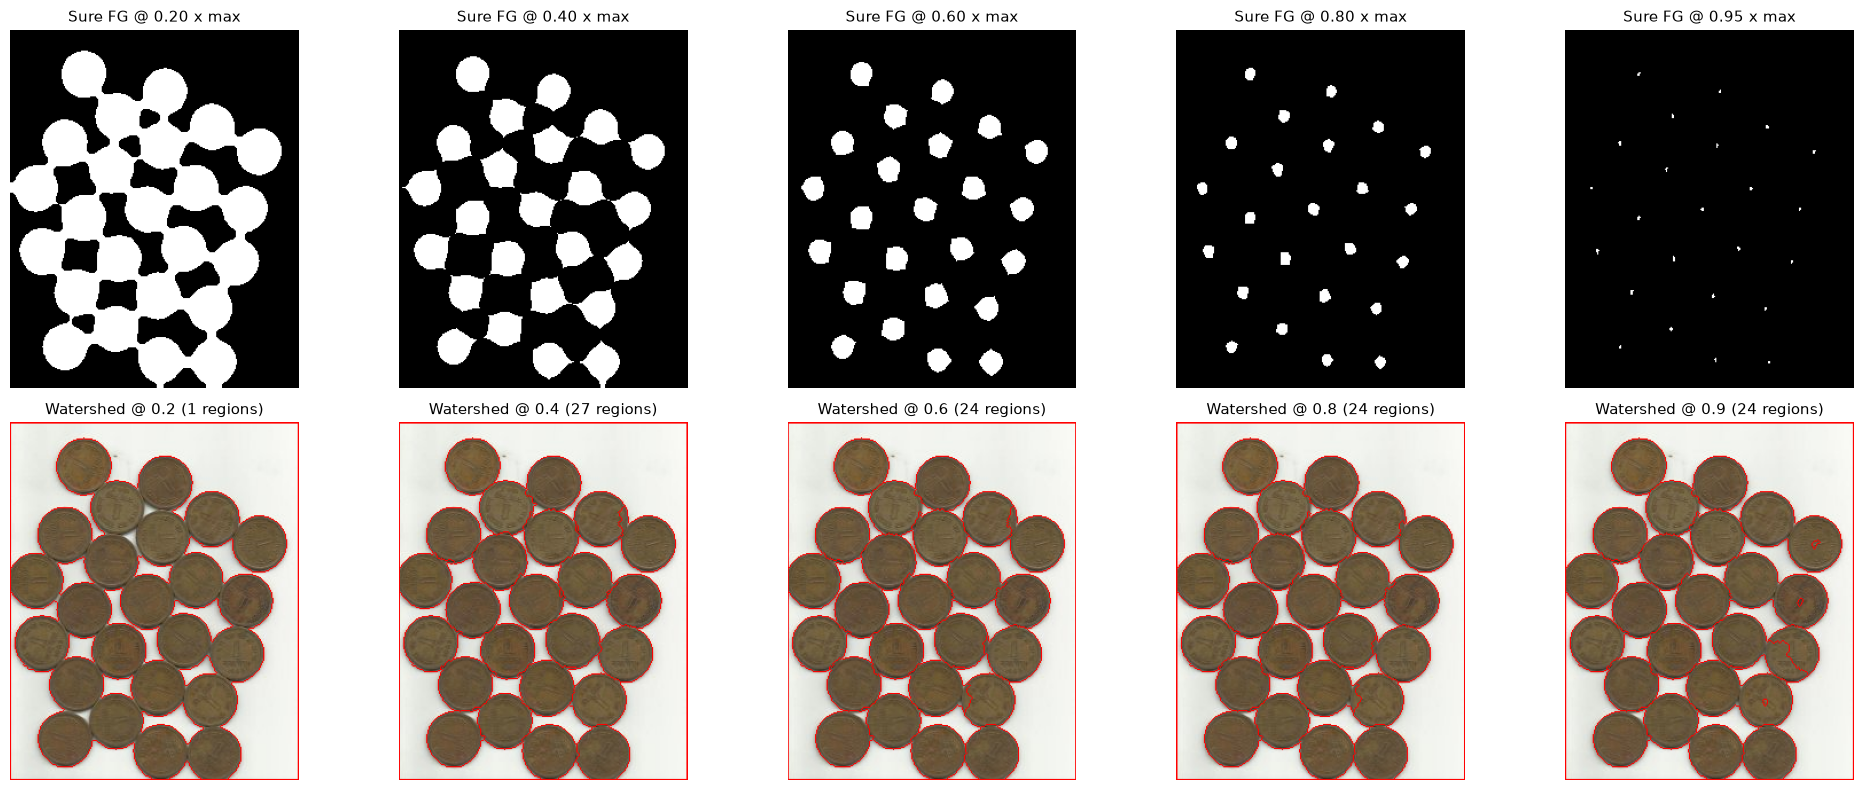

Experiment Distance Threshold  Foreground  Regions  
1          0.20 x max          1           1        
2          0.40 x max          27          27       
3          0.60 x max          24          24       
4          0.80 x max          24          24       
5          0.95 x max          24          24       


True

In [13]:
ratios = [0.2, 0.4, 0.6, 0.8, 0.95]        # distance-transform threshold as a fraction of max distance
runs = [watershed_coins(coins, r) for r in ratios]

show([r['sure_fg'] for r in runs] + [r['result'] for r in runs],
     [f'Sure FG @ {r:.2f} x max' for r in ratios] + [f'Watershed @ {r:.1f} ({x["n_regions"]} regions)'
                                                   for r, x in zip(ratios, runs)], cols=5)

print(f"{'Experiment':<11}{'Distance Threshold':<20}{'Foreground':<12}{'Regions':<9}")
for i, (r, x) in enumerate(zip(ratios, runs), 1):
    print(f"{i:<11}{f'{r:.2f} x max':<20}{x['n_fg']:<12}{x['n_regions']:<9}")

cv2.imwrite('outputs/task8_best_watershed.png', runs[2]['result'])

### Experiments (distance-transform threshold)

| Experiment | Distance threshold | Foreground markers | Regions | Observed result |
|---|---|---|---|---|
| 1 | 0.20 × max | 1 | 1 | Sure foreground is one connected blob → all coins merged into one region |
| 2 | 0.40 × max | 27 | 27 | 24 coin markers + 3 tiny 1–2 px specks at coin contact points → 3 false extra regions (over-split) |
| 3 | 0.60 × max | 24 | 24 | One clean marker per coin, correct boundaries |
| 4 | 0.80 × max | 24 | 24 | Correct, markers smaller |
| 5 | 0.95 × max | 24 | 24 | Still correct, but markers are only 4–9 px; a slightly smaller or less round coin would lose its marker and merge with a neighbour |

**Most meaningful range:** about **0.6 – 0.8 × max distance**. Below ~0.4 the necks between touching coins are still "sure foreground", so coins merge (or leave small fragments that split). Above ~0.9 the markers become tiny and fragile. In this range every coin has exactly one solid marker, and watershed separates all 24 coins.

## Task 9 — Segmenting an Image Using K-Means

K=2: unique colours 28661 -> 2 | cluster centres (BGR): [[60, 66, 90], [142, 148, 180]]


K=4: unique colours 28661 -> 4 | cluster centres (BGR): [[53, 56, 75], [115, 125, 166], [182, 182, 200], [70, 85, 117]]


K=6: unique colours 28661 -> 6 | cluster centres (BGR): [[62, 74, 103], [116, 130, 192], [191, 192, 208], [53, 54, 72], [85, 101, 136], [154, 146, 160]]


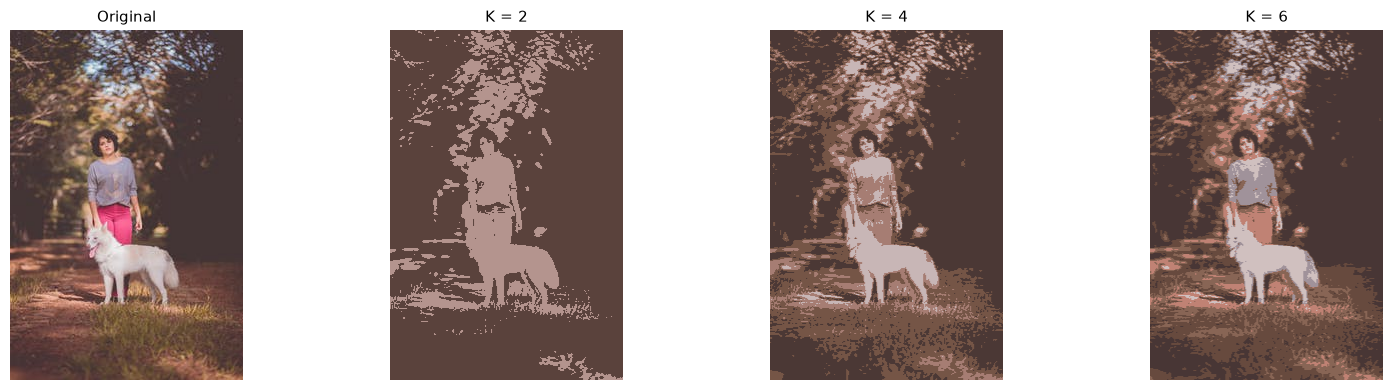

In [14]:
dog = cv2.imread('images/dog.jpeg')                          # 1. colour image

# 2-3. Every pixel becomes a 3-value feature vector (B, G, R) in float32 (what cv2.kmeans needs).
pixels = dog.reshape(-1, 3).astype(np.float32)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

results = []
for K in [2, 4, 6]:
    # 4. K-Means: 10 attempts with k-means++ starting centres, best one kept.
    _, labels, centers = cv2.kmeans(pixels, K, None, criteria, 10, cv2.KMEANS_PP_CENTERS)
    # 5. Rebuild the image: every pixel takes the colour of its cluster centre.
    seg = centers.astype(np.uint8)[labels.flatten()].reshape(dog.shape)
    results.append(seg)
    print(f'K={K}: unique colours {len(np.unique(pixels, axis=0))} -> {K} | cluster centres (BGR):',
          centers.astype(int).tolist())
    cv2.imwrite(f'outputs/task9_kmeans_K{K}.png', seg)

show([dog] + results, ['Original', 'K = 2', 'K = 4', 'K = 6'])

### Parameters

Features = (B, G, R) per pixel, `float32`; criteria = 100 iterations or ε = 0.2; 10 attempts with k-means++ initialisation.

| K | Colours (from 28 661 unique) | Visual difference from original | Major regions |
|---|---|---|---|
| 2 | 2 | Very large — a two-tone poster | Dark (trees, shadows, ground) vs light (sky gaps, dog, shirt, sunny path) |
| 4 | 4 | Scene recognisable, flat colours | Dark foliage, mid-brown ground/trunks, light-brown path, near-white (dog, shirt, sky) |
| 6 | 6 | Close to the original | Adds separate clusters for the pink trousers/warm tones and grey-violet shades; dog and woman clearly separated from the path |

**Colour simplification:** K = 2 reduces the image by ~99.99 % of its colours and loses all object identity; K = 4 keeps the main structure (dog vs ground vs trees); K = 6 is the smallest K where the woman's clothing and the dog become separate meaningful regions.

## Task 10 — Design a Segmentation System for an Unknown Image

**Image:** `smarties.png` — coloured sweets on a bright white background, with soft shadows and
specular highlights. Goal: separate every sweet from the background.

**Methods chosen:** Otsu's thresholding, HSV colour thresholding, K-Means.

Otsu threshold: 176.0
Cluster centres (BGR): [[253, 252, 252], [80, 87, 133]]


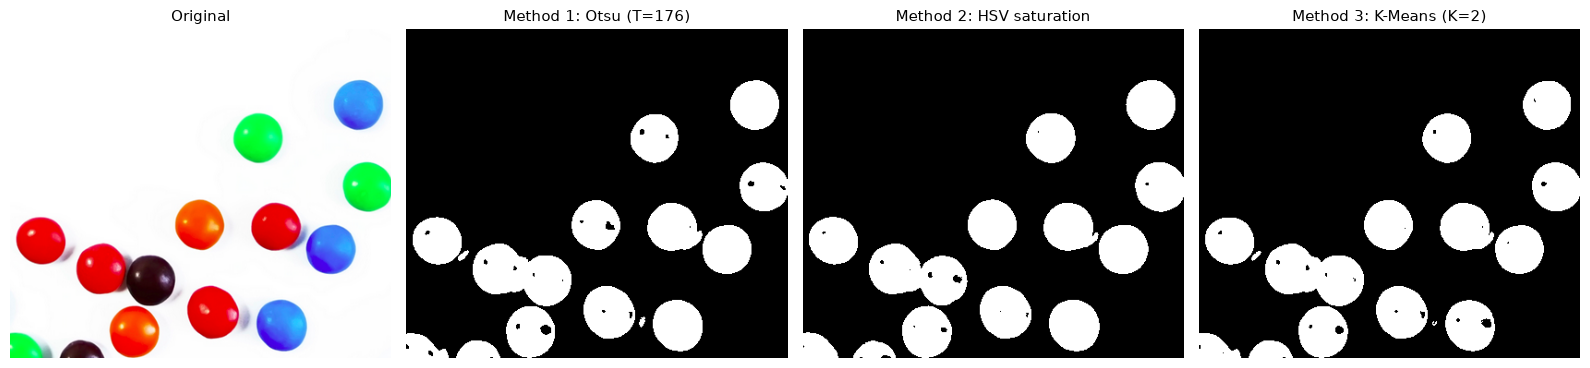

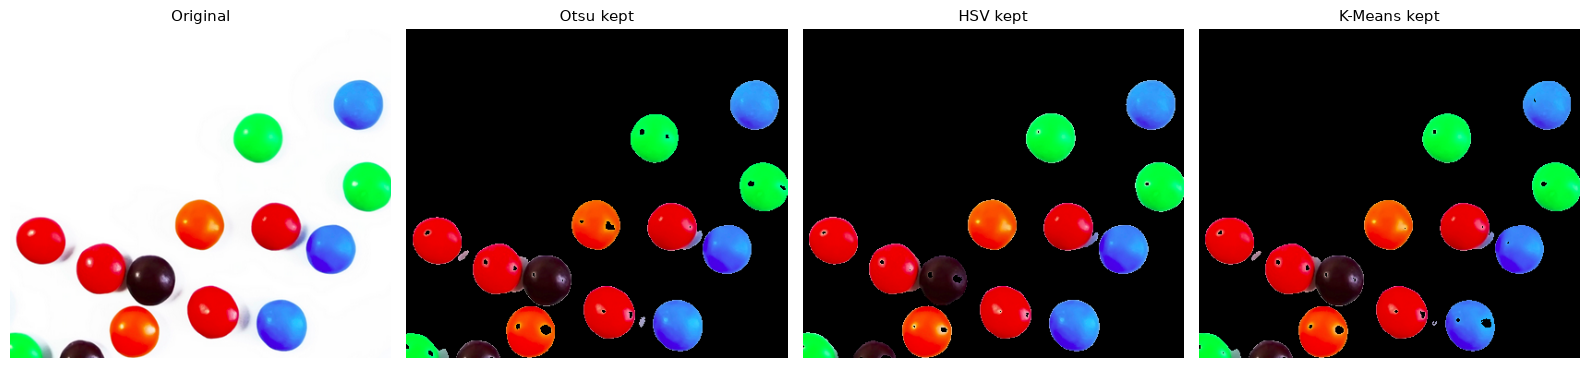

True

In [15]:
sm = cv2.imread('images/smarties.png')
gray = cv2.cvtColor(sm, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)

# Method 1 - Otsu: assumes two intensity classes (dark sweets vs bright background).
t_otsu, m1 = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Method 2 - Colour (HSV): assumes sweets are saturated colours and the background is unsaturated.
#            Any pixel with saturation > 80 counts as a sweet, whatever its hue.
m2 = cv2.inRange(hsv, np.array([0, 80, 0]), np.array([180, 255, 255]))

# Method 3 - K-Means (K=2 on BGR): assumes pixels form two colour groups.
px = sm.reshape(-1, 3).astype(np.float32)
_, lab, cen = cv2.kmeans(px, 2, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2),
                         10, cv2.KMEANS_PP_CENTERS)
bg = np.argmax(cen.sum(axis=1))                         # brightest centre = white background
m3 = np.where(lab.flatten() == bg, 0, 255).astype(np.uint8).reshape(gray.shape)

print('Otsu threshold:', t_otsu)
print('Cluster centres (BGR):', cen.astype(int).tolist())

overlay = lambda m: cv2.bitwise_and(sm, sm, mask=m)     # shows which pixels each method kept
show([sm, m1, m2, m3], ['Original', f'Method 1: Otsu (T={t_otsu:.0f})', 'Method 2: HSV saturation',
                        'Method 3: K-Means (K=2)'])
show([sm, overlay(m1), overlay(m2), overlay(m3)], ['Original', 'Otsu kept', 'HSV kept', 'K-Means kept'])

cv2.imwrite('outputs/task10_comparison.png', np.hstack([sm, cv2.merge([m1] * 3), cv2.merge([m2] * 3),
                                                         cv2.merge([m3] * 3)]))

### Method analysis

| | Otsu (grayscale) | HSV colour (S > 80) | K-Means (K = 2, BGR) |
|---|---|---|---|
| **Assumption** | Histogram has two intensity peaks (dark objects, bright background) | Objects are saturated colours, background is unsaturated (white/grey) | Pixels form two colour groups |
| **Correct** | All sweets including brown ones (T = 176) | All sweets; grey shadows correctly rejected | All sweets (centres: white (253,252,252) and average sweet colour (80,87,133)) |
| **Wrong** | Grey shadows next to sweets are darker than 176 → kept as "object" (586 px, mean saturation 53); white highlights become holes | Only the brightest pure-white highlight centres become small holes; it keeps 772 px of highlight/rim that Otsu loses | Same as Otsu: shadows grouped with sweets, highlight holes |
| **Most important parameter** | None to set — but result depends on shadow intensity (pre-blur/contrast) | Saturation lower bound (80): lower keeps shadows, higher cuts the shaded sides | K and the colour space; K = 2 forces shadows into one of the two groups |

### Conclusion

The **HSV saturation threshold** gave the most meaningful regions for this image. Comparing the masks pixel by pixel: the 586 px only Otsu keeps are the grey shadow crescents beside the sweets (low saturation 53), and the 772 px only HSV keeps are bright coloured highlights and rims of the sweets (saturation 134, brightness 247). So HSV is the only method that does not attach shadows to the sweets and keeps more of each sweet's surface. The property that makes it suitable is that the objects differ from the background by **colour saturation, not just brightness**: the background and the shadows are both unsaturated (only their brightness differs), while every sweet — whatever its hue — is strongly saturated. Otsu and K-Means both rely on brightness/colour distance, so the darker shadows fall on the object side of their decision boundary.